In [7]:
import numpy as np
import matplotlib.pyplot as plt
import pymc as pm
import pytensor.tensor as pt

# Константы из предыдущих задач
YIELD = 10000 # фотонов/МэВ
L_ATT = 8.0   # длина затухания в метрах
R_DET = 2.0   # радиус детектора
N_PMT = 40    # число ФЭУ
R_PMT = 0.1   # радиус ФЭУ
A_EFF = 0.5   # эффективность

In [8]:
i = np.arange(N_PMT) + 0.5
phi = np.arccos(1 - 2*i/N_PMT)
theta = np.pi * (1 + 5**0.5) * i

pmt_x = R_DET * np.sin(phi) * np.cos(theta)
pmt_y = R_DET * np.sin(phi) * np.sin(theta)
pmt_z = R_DET * np.cos(phi)

pmt_pos_np = np.stack([pmt_x, pmt_y, pmt_z], axis=1)
pmt_pos_tensor = pt.constant(pmt_pos_np.astype(np.float32))

N_photons = 12000 # чуть больше среднего (10000), чтобы статистика была лучше
phi_p = np.random.uniform(0, 2*np.pi, N_photons)
cos_t = np.random.uniform(-1, 1, N_photons)
sin_t = np.sqrt(1 - cos_t**2)

dirs_np = np.stack([sin_t*np.cos(phi_p), sin_t*np.sin(phi_p), cos_t], axis=1)
dirs_tensor = pt.constant(dirs_np.astype(np.float32))

source_pos = pt.constant(np.array([0.0, 0.0, 0.0], dtype=np.float32))

In [9]:
def calculate_charge(dirs, source_pos, use_attenuation):
    # 1. Пересечение луча и сферы
    # Уравнение: |source_pos + t*dir|^2 = R^2
    a = pt.sum(dirs**2, axis=1) 
    b = 2 * pt.dot(dirs, source_pos)
    c = pt.dot(source_pos, source_pos) - R_DET**2
    
    disc = b**2 - 4*a*c
    
    t_hit = (-b + pt.sqrt(pt.maximum(disc, 0))) / (2*a)
    
    hit_points = source_pos + t_hit[:, None] * dirs
    
    diff = hit_points[:, None, :] - pmt_pos_tensor[None, :, :]
    dists_sq = pt.sum(diff**2, axis=2)
    
    min_dist_sq = pt.min(dists_sq, axis=1)
    
    mask = pt.and_(disc >= 0, min_dist_sq <= R_PMT**2)
    
    if use_attenuation:
        dist_travel = pt.sqrt(pt.sum((hit_points - source_pos)**2, axis=1))
        prob = pt.exp(-dist_travel / L_ATT)
        
        survive = pt.random.uniform(size=prob.shape) < prob
        mask = pt.and_(mask, survive)
        
    n_hits = pt.sum(mask)
    pe_counts = pt.random.poisson(A_EFF, size=n_hits)
    
    return pt.sum(pe_counts)

Генерируем выборку (без затухания)...
Средний заряд (PyMC): 139.1 ± 11.7
Теоретическая оценка (Задача 4): 125.0


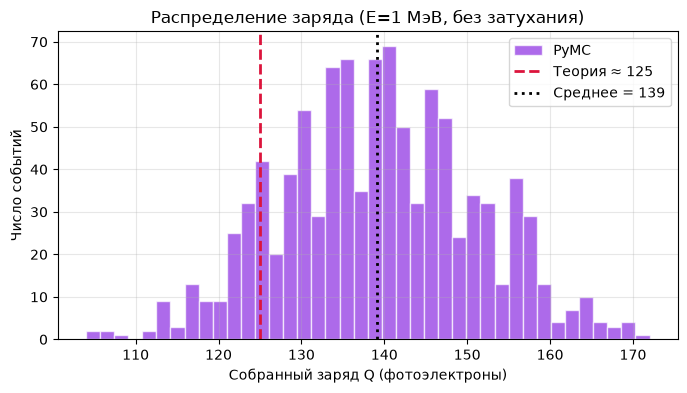

In [10]:
with pm.Model() as model_no_att:
    Q_no_att = calculate_charge(dirs_tensor, source_pos, use_attenuation=False)
    pm.Deterministic('Q_total', Q_no_att)

print("Генерируем выборку (без затухания)...")
charges_no_att = pm.draw(model_no_att.Q_total, draws=1000)

mean_q = np.mean(charges_no_att)
std_q = np.std(charges_no_att)

# Теоретическая оценка из задачи 4 (примерно 125)
Q_theor = A_EFF * YIELD * 1.0 * (N_PMT * R_PMT**2 / (4 * R_DET**2))

print(f"Средний заряд (PyMC): {mean_q:.1f} ± {std_q:.1f}")
print(f"Теоретическая оценка (Задача 4): {Q_theor:.1f}")

plt.figure(figsize=(8, 4))
plt.hist(charges_no_att, bins=40, alpha=0.7, color='blueviolet', edgecolor='white', label='PyMC')
plt.axvline(Q_theor, color='crimson', linestyle='--', linewidth=2, label=f'Теория ≈ {Q_theor:.0f}')
plt.axvline(mean_q, color='black', linestyle=':', linewidth=2, label=f'Среднее = {mean_q:.0f}')
plt.xlabel('Собранный заряд Q (фотоэлектроны)')
plt.ylabel('Число событий')
plt.title('Распределение заряда (E=1 МэВ, без затухания)')
plt.legend()
plt.grid(alpha=0.3)
plt.show()

Генерируем выборку (с затуханием)...
Средний заряд (с затуханием): 109.2 ± 11.1


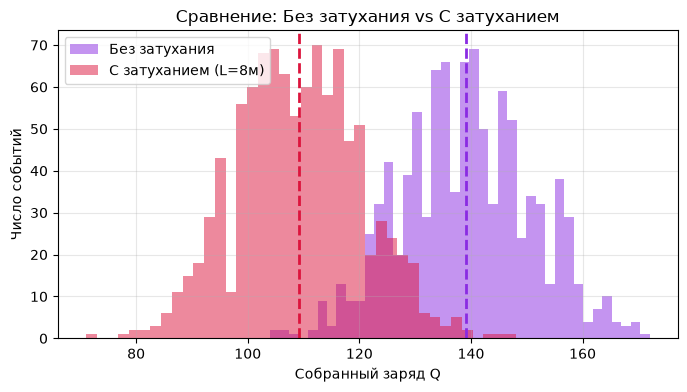


Отношение средних (с затуханием / без): 0.785


In [11]:
with pm.Model() as model_att:
    Q_att = calculate_charge(dirs_tensor, source_pos, use_attenuation=True)
    pm.Deterministic('Q_total_att', Q_att)

print("Генерируем выборку (с затуханием)...")
charges_att = pm.draw(model_att.Q_total_att, draws=1000)

mean_q_att = np.mean(charges_att)
std_q_att = np.std(charges_att)

print(f"Средний заряд (с затуханием): {mean_q_att:.1f} ± {std_q_att:.1f}")

plt.figure(figsize=(8, 4))
plt.hist(charges_no_att, bins=40, alpha=0.5, color='blueviolet', label='Без затухания')
plt.hist(charges_att, bins=40, alpha=0.5, color='crimson', label='С затуханием (L=8м)')
plt.axvline(mean_q, color='blueviolet', linestyle='--', linewidth=2)
plt.axvline(mean_q_att, color='crimson', linestyle='--', linewidth=2)
plt.xlabel('Собранный заряд Q')
plt.ylabel('Число событий')
plt.title('Сравнение: Без затухания vs С затуханием')
plt.legend()
plt.grid(alpha=0.3)
plt.show()

print(f"\nОтношение средних (с затуханием / без): {mean_q_att / mean_q:.3f}")